# Per-sample quality score for the uniform RNA-seq reprocessing


# Per-sample quality score for the uniform RNA-seq reprocessing

Instruction 72 (Einar, 2026-11-04): "there should also be a quality score for each expression sample." Every verified bulk RNA-seq run gets seven raw metrics, all measured the same way for every study, a score between 0 and 1 for each metric, and one overall quality (geometric mean of the available component scores) with plain-language flags. **Version 0:** the anchors below are a first guess and will be revisited.

Why a geometric mean: a run is only as good as its weak spot. A library with plenty of reads but almost no parasite in it, or with perfect depth but a replicate that disagrees with its siblings, should not be rescued by its other good numbers. A low value in any one component pulls the overall quality down.

## 1 · The metrics, in plain language

* **Total reads processed** (reported, not scored): how many sequencing reads went in.

* **Mapping rate** (scored): fraction of reads that salmon could place on the combined parasite + host reference. Low values mean contamination (bacteria, mycoplasma), adapters, rRNA or a wrong reference.

* **Parasite reads** (scored, log scale): reads assigned to Toxoplasma genes. Most libraries are infected host cells, so the parasite may be a small slice; below roughly 100,000 parasite reads, lowly expressed genes are mostly noise.

* **Parasite share of mapped reads** (reported, not scored, to avoid double counting depth): 1 minus host share. Shows whether low parasite depth is due to a small library or to a host-dominated one.

* **Parasite genes detected** (scored): genes with TPM of at least 1 out of about 8,157. A healthy deep library sees most expressed genes; a thin or damaged one sees few.

* **Compatible fragment ratio** (scored): fraction of fragments whose orientation fits the library type salmon inferred. Values near 1 mean a clean stranded/unstranded library; low values hint at mixed protocols, genomic DNA or mislabelled strandedness.

* **Salmon vs kallisto agreement** (scored): Spearman correlation of parasite gene TPM from two independent quantifiers on the same reads. Disagreement means the gene values depend on the algorithm, i.e. the signal is weak or the reads ambiguous.

* **Replicate agreement** (scored): Spearman correlation of log2(TPM+1) with the median profile of the other runs of the same study and condition group (needs at least two others). A run that does not resemble its replicates is a technical outlier or mis-grouped. Only available where grouping provides replicates.

## 2 · Inputs

Newest app snapshot that has rna/snapshot.json; matrices are the salmon ME49_host parasite-gene tables with TPM re-closed over parasite genes. Per-run salmon and kallisto files are read from the uniform pipeline output; nothing under the excluded single-cell folder is read.

In [1]:
import json, re, gzip
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import spearmanr
BASE = Path('/nas_mnt/carruthers/Einar/parascape_omics')
SNAP_ROOT = BASE / 'app_snapshots'
snap = sorted(p for p in SNAP_ROOT.iterdir() if re.fullmatch(r'\d{8}T\d{6}Z-\d+', p.name) and (p / 'rna/snapshot.json').exists())[-1]
meta = json.loads((snap / 'rna/snapshot.json').read_text())
RUNS = BASE / 'rnaseq'
OUT = Path('results/rna_sample_quality_2026_11_06'); OUT.mkdir(parents=True, exist_ok=True)
design = pd.read_csv(snap / 'rna/sample_design.tsv', sep='\t', dtype=str)
design['key'] = design.study + '/' + design.run_accession; design = design.set_index('key')
print(snap.name, meta['verified_runs'], 'verified runs in snapshot')
tx2gene = pd.read_csv(BASE / 'references/ME49_host/tx2gene.tsv', sep='\t', header=None, names=['tx', 'gene']).set_index('tx').gene

20261107T012052Z-735 735 verified runs in snapshot


## 3 · Raw metrics per run

Matrix-derived metrics come from the snapshot (the numbers users actually get); mapping and library-type metrics come from the run salmon files. Kallisto transcripts are summed to genes with the same transcript-to-gene table; only parasite genes are compared (the kallisto index contains the host too), and TPM scale differences do not matter for a rank correlation.

In [2]:
rows, logs, tpms = [], {}, {}
for f in sorted((snap / 'rna/matrices').glob('*/salmon_ME49_host.parquet')):
    study = f.parent.name; m = pd.read_parquet(f)
    smp = pd.read_csv(f.parent / 'salmon_ME49_host_samples.tsv', sep='\t', dtype=str).set_index('run_accession')
    for run in m['count'].columns:
        cnt, tpm = m['count'][run].astype(float), m['tpm'][run].astype(float)
        hs = smp['host_share'].get(run) if 'host_share' in smp else None
        rows.append(dict(key=study + '/' + run, run=run, study=study, parasite_reads=cnt.sum(), genes_detected=int((tpm >= 1).sum()),
                         n_genes=len(tpm), host_share=float(hs) if hs not in (None, '') and pd.notna(hs) else np.nan))
        tpms[study + '/' + run] = tpm
q = pd.DataFrame(rows).set_index('key')
q['parasite_share'] = 1 - q.host_share
q = q.join(design[['condition_group', 'replicate_label', 'control_role']])
def salmon_stats(r):
    d = RUNS / q.loc[r, 'study'] / q.loc[r, 'run'] / 'salmon_ME49_host'
    out = dict(total_reads=np.nan, mapping_rate=np.nan, compatible_ratio=np.nan)
    try:
        mi = json.loads((d / 'aux_info/meta_info.json').read_text())
        out['total_reads'] = mi['num_processed']; out['mapping_rate'] = mi['percent_mapped'] / 100
    except Exception: pass
    try: out['compatible_ratio'] = json.loads((d / 'lib_format_counts.json').read_text())['compatible_fragment_ratio']
    except Exception: pass
    return out
q = q.join(pd.DataFrame({r: salmon_stats(r) for r in q.index}).T.astype(float))
def kallisto_corr(r):
    p = RUNS / q.loc[r, 'study'] / q.loc[r, 'run'] / 'kallisto_ME49_host' / 'abundance.tsv.gz'
    if not p.exists(): p = p.with_suffix('')
    if not p.exists(): return np.nan
    try: k = pd.read_csv(p, sep='\t', index_col=0)
    except Exception: return np.nan
    g = k.tpm.groupby(tx2gene.reindex(k.index).values).sum()
    both = tpms[r].index.intersection(g.index)
    return spearmanr(tpms[r][both], g[both])[0] if len(both) > 100 else np.nan
q['salmon_kallisto_rho'] = [kallisto_corr(r) for r in q.index]
print(len(q), 'runs;', q.salmon_kallisto_rho.notna().sum(), 'with kallisto;', q.mapping_rate.notna().sum(), 'with salmon meta;',
      q.compatible_ratio.notna().sum(), 'with library type;', q.host_share.notna().sum(), 'with host share')

717 runs; 668 with kallisto; 717 with salmon meta; 717 with library type; 668 with host share


### Replicate agreement

Groups are study x `condition_group` from the sample design. For a run with at least two other group members, the reference is the per-gene median of log2(TPM+1) over the others; the metric is the Spearman correlation over genes expressed (TPM at least 1) in the run or the reference, so the thousands of silent genes do not inflate agreement. Runs with a duplicate or missing group give NaN.

In [3]:
L = pd.DataFrame({r: np.log2(t + 1) for r, t in tpms.items()})
q['group_size'] = q.groupby(['study', 'condition_group'], dropna=True).study.transform('size').where(q.condition_group.notna())
def rep_corr(r):
    if pd.isna(q.loc[r, 'condition_group']): return np.nan
    others = q.index[(q.study == q.loc[r, 'study']) & (q.condition_group == q.loc[r, 'condition_group']) & (q.index != r)]
    if len(others) < 2: return np.nan
    ref = L[others].median(axis=1); x = L[r]
    keep = (x > np.log2(2)) | (ref > np.log2(2))
    return spearmanr(x[keep], ref[keep])[0] if keep.sum() > 100 else np.nan
q['replicate_rho'] = [rep_corr(r) for r in q.index]
print('runs with replicate agreement:', q.replicate_rho.notna().sum(), 'of', len(q))
q[['parasite_reads', 'genes_detected', 'mapping_rate', 'compatible_ratio', 'salmon_kallisto_rho', 'replicate_rho']].describe().round(3)

runs with replicate agreement: 442 of 717


,parasite_reads,genes_detected,mapping_rate,compatible_ratio,salmon_kallisto_rho,replicate_rho
count,717,717,717,717,668,442
mean,1.586e+07,6437,0.715,0.98,0.941,0.971
std,1.915e+07,1905,0.25,0.043,0.049,0.065
min,0,0,0,0.502,0.523,0.277
25%,3.387e+06,6570,0.683,0.97,0.925,0.977
50%,1.37e+07,6860,0.809,0.996,0.954,0.989
75%,1.995e+07,7278,0.86,1,0.97,0.996
max,1.81e+08,8075,0.967,1,0.987,0.999


## 4 · Anchors, component scores and the quality

Each metric is mapped linearly to 0 (at the low anchor) and 1 (at the high anchor), clipped, with the same anchors for every study. Quality is the geometric mean of the available component scores, each floored at 0.01 so one zero does not erase the run entirely but still drags it to near zero. `n_components` says how many scores entered; runs with fewer than 3 are marked in the flags.

| metric | score 0 at | score 1 at |
|---|---|---|
| parasite reads (log10) | 1e5 | 1e7 |
| parasite genes detected | 3,000 | 7,000 |
| mapping rate | 0.30 | 0.80 |
| compatible fragment ratio | 0.80 | 0.98 |
| salmon-kallisto Spearman | 0.80 | 0.98 |
| replicate Spearman | 0.80 | 0.98 |

In [4]:
ANCHORS = {'parasite_reads': (5, 7, 'log10'), 'genes_detected': (3000, 7000, None), 'mapping_rate': (0.3, 0.8, None),
           'compatible_ratio': (0.8, 0.98, None), 'salmon_kallisto_rho': (0.8, 0.98, None), 'replicate_rho': (0.8, 0.98, None)}
SC = {}
for k, (lo, hi, tr) in ANCHORS.items():
    v = np.log10(q[k].clip(lower=1)) if tr == 'log10' else q[k]
    q['s_' + k] = ((v - lo) / (hi - lo)).clip(0, 1)
    SC[k] = 's_' + k
def gmean(cols):
    s = q[cols].clip(lower=0.01)
    return np.exp(np.log(s).mean(axis=1, skipna=True)).where(s.notna().any(axis=1))
q['n_components'] = q[list(SC.values())].notna().sum(axis=1)
q['quality'] = gmean(list(SC.values()))
q['quality_no_replicate'] = gmean([c for k, c in SC.items() if k != 'replicate_rho'])
REASONS = [('parasite_reads', lambda v: v < 1e6, 'low parasite depth'), ('genes_detected', lambda v: v < 4000, 'few parasite genes detected'),
           ('mapping_rate', lambda v: v < 0.5, 'low mapping rate'), ('compatible_ratio', lambda v: v < 0.9, 'library type inconsistent'),
           ('salmon_kallisto_rho', lambda v: v < 0.9, 'salmon and kallisto disagree'), ('replicate_rho', lambda v: v < 0.9, 'replicate outlier'),
           ('parasite_share', lambda v: v < 0.02, 'host-dominated library')]
def flags(r):
    out = [msg for k, f, msg in REASONS if pd.notna(r[k]) and f(r[k])]
    if r.n_components < 3: out.append('fewer than 3 components scored')
    return '; '.join(out)
q['flags'] = q.apply(flags, axis=1)
print(q.n_components.value_counts().sort_index().to_string())
q.quality.describe().round(3)

n_components
4     49
5    226
6    442


count    717.000
mean       0.795
std        0.283
min        0.025
25%        0.794
50%        0.916
75%        0.967
max        1.000

## 5 · Distributions per study

Boxes show the quality of each run by study (ordered by median). A study that is low as a whole usually has a systematic cause (a thin dataset, host-dominated libraries), not a few bad runs; this is exactly what a study-independent anchor should reveal.

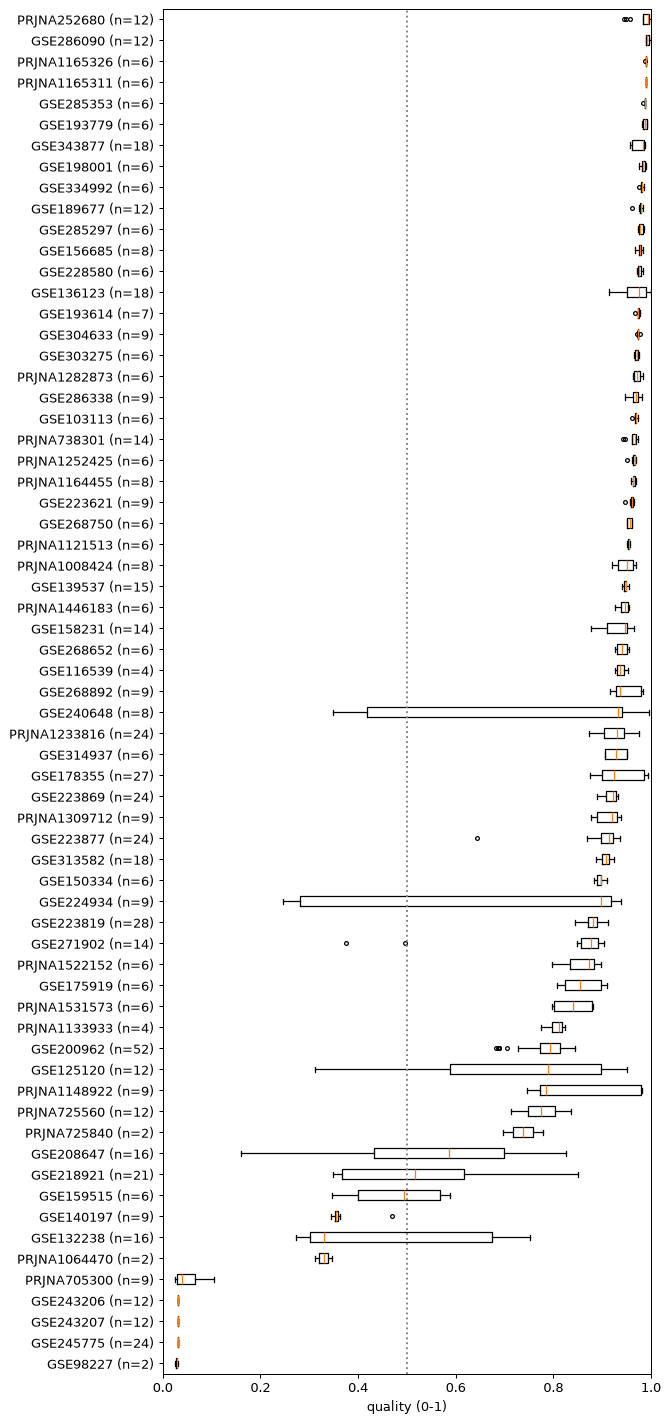

In [5]:
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
order = q.groupby('study').quality.median().sort_values().index
fig, ax = plt.subplots(figsize=(7, 0.28 * len(order) + 1.5))
ax.boxplot([q.loc[q.study == s, 'quality'].dropna() for s in order], vert=False, tick_labels=[f'{s} (n={int((q.study == s).sum())})' for s in order], flierprops=dict(markersize=3))
ax.set_xlabel('quality (0-1)'); ax.set_xlim(0, 1); ax.axvline(0.5, ls=':', c='grey')
fig

In [6]:
per = q.groupby('study').agg(runs=('quality', 'size'), median_quality=('quality', 'median'), min_quality=('quality', 'min'),
                           flagged=('flags', lambda s: int((s != '').sum())), median_parasite_reads=('parasite_reads', 'median'),
                           median_genes=('genes_detected', 'median'), median_parasite_share=('parasite_share', 'median')).sort_values('median_quality')
per.round(3)

,runs,median_quality,min_quality,flagged,median_parasite_reads,median_genes,median_parasite_share
study,,,,,,,
GSE98227,2,0.028,0.025,2,52.5,0.5,1
GSE245775,24,0.032,0.032,24,0,0,NaN
GSE243207,12,0.032,0.032,12,0,0,NaN
GSE243206,12,0.032,0.032,12,0,0,NaN
PRJNA705300,9,0.039,0.025,9,4735,1176,0.31
PRJNA1064470,2,0.329,0.312,2,2.191e+06,6658,0.329
GSE132238,16,0.33,0.274,16,4.569e+07,7834,0.941
GSE140197,9,0.355,0.344,9,3.048e+06,6487,0.129
GSE159515,6,0.494,0.347,6,7.769e+06,6764,0.792


## 6 · The 20 worst runs

With the reasons that triggered flags (thresholds: parasite reads < 1e6, genes < 4,000, mapping < 0.5, compatible ratio < 0.9, salmon-kallisto < 0.9, replicate < 0.9, parasite share < 2 %).

In [7]:
w = q.sort_values('quality').head(20)
w[['study', 'condition_group', 'quality', 'n_components', 'parasite_reads', 'genes_detected', 'mapping_rate', 'replicate_rho', 'flags']].round(3)

,study,condition_group,quality,n_components,parasite_reads,genes_detected,mapping_rate,replicate_rho,flags
key,,,,,,,,,
GSE98227/SRR5482434,GSE98227,time point: 3 passages after transfection | B4_P3.fastq,0.025,5,105,1,0,NaN,low parasite depth; few parasite genes detected; low mapping rate; salmon and kallisto disagree
PRJNA705300/SRR13799561,PRJNA705300,strain: RH; treatment: none; tissue: HFF cell culture | Model organism or animal sample from Toxoplasma gondii,0.025,5,2400,788,0.294,NaN,low parasite depth; few parasite genes detected; low mapping rate; salmon and kallisto disagree
PRJNA705300/SRR13799562,PRJNA705300,strain: RH; treatment: none; tissue: HFF cell culture | Model organism or animal sample from Toxoplasma gondii,0.025,5,5304,1176,0.267,NaN,low parasite depth; few parasite genes detected; low mapping rate; salmon and kallisto disagree
PRJNA705300/SRR13799553,PRJNA705300,strain: RH; treatment: IAA-24h; tissue: HFF cell culture | Model organism or animal sample from Toxoplasma gondii,0.03,6,686,353,0.336,0.356,low parasite depth; few parasite genes detected; low mapping rate; salmon and kallisto disagree; replicate outlier
GSE243206/SRR26060419,GSE243206,eIF4E1_IAA_RNAseq,0.032,4,0,0,0,NaN,low parasite depth; few parasite genes detected; low mapping rate
GSE245775/SRR26440473,GSE245775,"treatment: DMEM pH7.4, 5%CO2 | parental_tachyzoite_RIBOseq",0.032,4,0,0,0,NaN,low parasite depth; few parasite genes detected; low mapping rate
GSE243206/SRR26060427,GSE243206,eIF4E1_control_RIBOseq,0.032,4,0,0,0,NaN,low parasite depth; few parasite genes detected; low mapping rate
GSE243206/SRR26060426,GSE243206,eIF4E1_control_RIBOseq,0.032,4,0,0,0,NaN,low parasite depth; few parasite genes detected; low mapping rate
GSE243207/SRR26060422,GSE243207,eIF4E1_control_RNAseq,0.032,4,0,0,0,NaN,low parasite depth; few parasite genes detected; low mapping rate


In [8]:
print('flagged:', int((q['flags'] != '').sum()), 'of', len(q))
from collections import Counter
c = Counter(m for f in q['flags'] for m in f.split('; ') if m)
pd.Series(c).sort_values(ascending=False).rename('runs').to_frame()

flagged: 176 of 717


,runs
low parasite depth,112
low mapping rate,100
few parasite genes detected,56
salmon and kallisto disagree,54
replicate outlier,28
host-dominated library,24
library type inconsistent,10


## 7 · Does the score predict replicate agreement? (replicate agreement left out)

The honest test of whether the score means anything: build the quality from every component except replicate agreement, then ask whether it ranks runs by how well they match their replicates, which the score never saw. We also report it after removing the study mean of both quantities, so a between-study difference alone cannot create the correlation.

{'runs': 442, 'studies': 41, 'spearman_all': np.float64(0.496), 'p_all': np.float64(7.492849401358853e-29), 'spearman_within_study': np.float64(0.373), 'p_within': np.float64(4.908554145672137e-16)}
component-wise Spearman with replicate agreement: {'parasite_reads': np.float64(0.554), 'genes_detected': np.float64(0.168), 'mapping_rate': np.float64(0.208), 'compatible_ratio': np.float64(0.101), 'salmon_kallisto_rho': np.float64(0.373)}


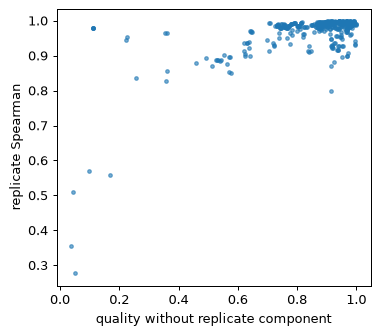

In [9]:
t = q.dropna(subset=['replicate_rho', 'quality_no_replicate'])
rho_all, p_all = spearmanr(t.quality_no_replicate, t.replicate_rho)
tw = t.assign(a=t.quality_no_replicate - t.groupby('study').quality_no_replicate.transform('mean'), b=t.replicate_rho - t.groupby('study').replicate_rho.transform('mean'))
rho_in, p_in = spearmanr(tw.a, tw.b)
res = {'runs': len(t), 'studies': t.study.nunique(), 'spearman_all': round(rho_all, 3), 'p_all': p_all, 'spearman_within_study': round(rho_in, 3), 'p_within': p_in}
dep = {k: round(spearmanr(t[c], t.replicate_rho)[0], 3) for k, c in SC.items() if k != 'replicate_rho'}
print(res); print('component-wise Spearman with replicate agreement:', dep)
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.scatter(t.quality_no_replicate, t.replicate_rho, s=8, alpha=.6)
ax.set_xlabel('quality without replicate component'); ax.set_ylabel('replicate Spearman')
fig

**Reading it:** a positive correlation means the cheap, replicate-free metrics (depth, mapping, library type, quantifier agreement) carry real information about reproducibility. A weak or near-zero value would say the score is mostly bookkeeping and the replicate component is not redundant. See the numbers above and the README for the plain conclusion.

## 8 · Write outputs

In [10]:
cols = ['study', 'condition_group', 'total_reads', 'mapping_rate', 'parasite_reads', 'host_share', 'parasite_share', 'genes_detected',
        'compatible_ratio', 'salmon_kallisto_rho', 'replicate_rho', 'group_size'] + list(SC.values()) + ['n_components', 'quality', 'quality_no_replicate', 'flags']
q.index.name = 'key'
q[['run'] + cols].sort_values(['study', 'run']).to_csv(OUT / 'sample_quality.tsv', sep='\t', index=False, float_format='%.5g')
qs = q.quality.quantile([.25, .5, .75]).round(3).tolist()
readme = f'''# Per-sample RNA-seq quality (v0, {DATE.replace("_", "-")})

Built by scripts/build_rna_sample_quality_notebook.py (notebook: notebooks/rna_sample_quality_{DATE}.ipynb) from snapshot {snap.name}.
{len(q)} verified runs scored; quality quartiles {qs[0]} / {qs[1]} / {qs[2]}; {int((q['flags'] != '').sum())} flagged.

## Formula
Each metric is mapped linearly to [0,1] between fixed anchors (same for every study), clipped. Quality = geometric mean of the available
component scores (each floored at 0.01); `n_components` is how many entered (1 to 6). `quality_no_replicate` omits replicate agreement and is used for the leave-out check.

| component | score 0 | score 1 |
|---|---|---|
| parasite reads (sum of counts in salmon ME49_host matrix, log10) | 1e5 | 1e7 |
| parasite genes with TPM >= 1 (of {int(q.n_genes.iloc[0])}) | 3000 | 7000 |
| mapping rate (salmon percent_mapped / 100, combined parasite + host reference) | 0.30 | 0.80 |
| compatible fragment ratio (salmon lib_format_counts) | 0.80 | 0.98 |
| salmon vs kallisto Spearman of parasite gene TPM | 0.80 | 0.98 |
| replicate Spearman (log2 TPM+1 vs median of other runs of study x condition_group, >= 2 others, genes TPM >= 1 in either) | 0.80 | 0.98 |

Reported but not scored: total reads, host share, parasite share of mapped reads (1 - host_share).
Flags: parasite reads < 1e6; genes < 4000; mapping < 0.5; compatible ratio < 0.9; salmon-kallisto < 0.9; replicate < 0.9; parasite share < 2%; fewer than 3 components.

## Leave-out check
Quality without the replicate component vs replicate agreement (n={res['runs']} runs in {res['studies']} studies): Spearman {res['spearman_all']} overall, {res['spearman_within_study']} after removing study means.

## Caveats (v0)
* Anchors are a first guess, not fitted; revisit once more studies are verified and the score distribution is known.
* Replicate agreement depends on `condition_group` being a true replicate grouping; the design marks many groupings as needing review, and a wrong grouping looks like a bad replicate.
* Mapping rate is on the combined parasite + host reference, so it does not say how well the parasite alone was captured; parasite depth and share cover that.
* A run in a low-replicate study has fewer components and its score is less constrained; check n_components.
* Biological differences between conditions inside a group (time courses grouped together) lower replicate agreement without being technical problems.
'''
(OUT / 'README.md').write_text(readme)
print(readme[:300])

# Per-sample RNA-seq quality (v0, 2026-11-06)

Built by scripts/build_rna_sample_quality_notebook.py (notebook: notebooks/rna_sample_quality_2026_11_06.ipynb) from snapshot 20261107T012052Z-735.
717 verified runs scored; quality quartiles 0.794 / 0.916 / 0.967; 176 flagged.

## Formula
Each metric i
